<a href="https://colab.research.google.com/github/nurlanrahimli1996/Nurlan-Portfolio/blob/main/Credit_Risk_Portfolio_Monitoring_%26_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Credit Risk Portfolio Monitoring & Analysis

Lending Club Loan Portfolio | 2007–2018
Business Objective

Using public consumer lending data to simulate a credit-risk reporting environment.

The analysis focuses on:

portfolio composition and exposure
loan performance and charge-offs
borrower risk characteristics
credit grade and FICO segmentation
concentration analysis
vintage trends
data quality and reconciliation
actionable reporting for credit-risk managers
This is a portfolio project based on public Lending Club data and is not U.S. Bank data.

# Project summary

**Dataset**
- I am using the Lending Club loan dataset.
- Each row represents an individual consumer loan.
- The data includes:
  - loan amount
  - loan term
  - interest rate
  - borrower income
  - debt-to-income ratio
  - FICO-related credit score information
  - loan grade
  - loan purpose
  - loan status

**Main Business Problem**
- The main objective is to understand credit portfolio risk.
- I want to identify where credit risk is concentrated across the loan portfolio.
- I also want to understand which borrower and loan characteristics are associated with a higher probability of poor loan performance.

**Key Questions**
- Which credit grades have the highest charge-off rates?
- How does FICO score relate to loan performance?
- Does a higher debt-to-income ratio indicate higher risk?
- Are certain loan purposes riskier than others?
- Are longer-term loans riskier than shorter-term loans?
- How does loan performance change over time and across origination periods?
- Are there any important data-quality issues that could affect reporting?

**Analytical Approach**
- Clean and validate the raw loan data.
- Separate resolved loans from active loans.
- Create clear credit-risk outcome categories.
- Calculate portfolio-level risk metrics.
- Segment the portfolio by borrower and loan characteristics.
- Compare charge-off rates across different groups.
- Analyse performance trends over time.
- Build a reporting dataset suitable for visualization and dashboarding.

**Final Goal**
- Build a practical credit risk portfolio monitoring analysis.
- Produce insights that could help a credit risk manager:
  - monitor loan performance
  - identify higher-risk segments
  - detect areas of portfolio concentration
  - support reporting and decision-making
  - improve the consistency and reliability of credit risk reporting

In [3]:
#Downloading the Kaggle dataset in Colab
!pip -q install kagglehub

In [4]:
import kagglehub
import os
import glob

path = kagglehub.dataset_download("wordsforthewise/lending-club")

print("Dataset location:", path)
print(os.listdir(path))

Using Colab cache for faster access to the 'lending-club' dataset.
Dataset location: /kaggle/input/lending-club
['rejected_2007_to_2018Q4.csv.gz', 'accepted_2007_to_2018Q4.csv.gz', 'accepted_2007_to_2018q4.csv', 'rejected_2007_to_2018q4.csv']


In [5]:
# Finding the accepted-loans file:
files = glob.glob(path + "/*")

for file in files:
    print(file)

/kaggle/input/lending-club/rejected_2007_to_2018Q4.csv.gz
/kaggle/input/lending-club/accepted_2007_to_2018Q4.csv.gz
/kaggle/input/lending-club/accepted_2007_to_2018q4.csv
/kaggle/input/lending-club/rejected_2007_to_2018q4.csv


In [6]:
# Loading the accepted-loans data
import pandas as pd
import numpy as np
import glob
import os

# Find files matching the pattern
matched_paths = glob.glob(path + "/*accepted*")

# Filter to find the target file (could be .csv or .csv.gz)
accepted_file = None
for p in matched_paths:
    if p.endswith(('.csv', '.csv.gz')):
        accepted_file = p
        break

if accepted_file:
    print("Loading file:", accepted_file)
    # pandas handles gzip compression automatically
    df = pd.read_csv(
        accepted_file,
        low_memory=False
    )
    print("Dataframe shape:", df.shape)
else:
    print("No accepted loans file found!")

Loading file: /kaggle/input/lending-club/accepted_2007_to_2018Q4.csv.gz
Dataframe shape: (2260701, 151)


In [7]:
# ============================================================
# 0. IMPORTING ONLY REQUIRED COLUMNS
# ============================================================

selected_columns = [
    "id",
    "loan_amnt",
    "term",
    "int_rate",
    "grade",
    "sub_grade",
    "annual_inc",
    "dti",
    "fico_range_low",
    "fico_range_high",
    "purpose",
    "issue_d",
    "loan_status"
]

df = pd.read_csv(
    accepted_file,
    usecols=selected_columns,
    low_memory=False
)

In [8]:
df.head()

,id,loan_amnt,term,int_rate,grade,sub_grade,annual_inc,issue_d,loan_status,purpose,dti,fico_range_low,fico_range_high
0,68407277,3600.0,36 months,13.99,C,C4,55000.0,Dec-2015,Fully Paid,debt_consolidation,5.91,675.0,679.0
1,68355089,24700.0,36 months,11.99,C,C1,65000.0,Dec-2015,Fully Paid,small_business,16.06,715.0,719.0
2,68341763,20000.0,60 months,10.78,B,B4,63000.0,Dec-2015,Fully Paid,home_improvement,10.78,695.0,699.0
3,66310712,35000.0,60 months,14.85,C,C5,110000.0,Dec-2015,Current,debt_consolidation,17.06,785.0,789.0
4,68476807,10400.0,60 months,22.45,F,F1,104433.0,Dec-2015,Fully Paid,major_purchase,25.37,695.0,699.0


In [10]:
print(f"Rows: {df.shape[0]:,}")
print(f"Columns: {df.shape[1]:,}")

Rows: 2,260,701
Columns: 13


In [11]:
df["loan_status"].value_counts(dropna=False)

,count
loan_status,
Fully Paid,1076751
Current,878317
Charged Off,268559
Late (31-120 days),21467
In Grace Period,8436
Late (16-30 days),4349
Does not meet the credit policy. Status:Fully Paid,1988
Does not meet the credit policy. Status:Charged Off,761
Default,40


In [13]:
# to see column/variable list

df.columns.tolist()

['id',
 'loan_amnt',
 'term',
 'int_rate',
 'grade',
 'sub_grade',
 'annual_inc',
 'issue_d',
 'loan_status',
 'purpose',
 'dti',
 'fico_range_low',
 'fico_range_high']

In [14]:
#Looking at the first 10 rows of selected variables

df[[
    "loan_amnt",
    "term",
    "int_rate",
    "grade",
    "sub_grade",
    "annual_inc",
    "dti",
    "fico_range_low",
    "fico_range_high",
    "loan_status"
]].head(10)

,loan_amnt,term,int_rate,grade,sub_grade,annual_inc,dti,fico_range_low,fico_range_high,loan_status
0,3600.0,36 months,13.99,C,C4,55000.0,5.91,675.0,679.0,Fully Paid
1,24700.0,36 months,11.99,C,C1,65000.0,16.06,715.0,719.0,Fully Paid
2,20000.0,60 months,10.78,B,B4,63000.0,10.78,695.0,699.0,Fully Paid
3,35000.0,60 months,14.85,C,C5,110000.0,17.06,785.0,789.0,Current
4,10400.0,60 months,22.45,F,F1,104433.0,25.37,695.0,699.0,Fully Paid
5,11950.0,36 months,13.44,C,C3,34000.0,10.20,690.0,694.0,Fully Paid
6,20000.0,36 months,9.17,B,B2,180000.0,14.67,680.0,684.0,Fully Paid
7,20000.0,36 months,8.49,B,B1,85000.0,17.61,705.0,709.0,Fully Paid
8,10000.0,36 months,6.49,A,A2,85000.0,13.07,685.0,689.0,Fully Paid
9,8000.0,36 months,11.48,B,B5,42000.0,34.80,700.0,704.0,Fully Paid


In [15]:
# Getting basic descriptive statistics

df[[
    "loan_amnt",
    "annual_inc",
    "dti",
    "fico_range_low",
    "fico_range_high"
]].describe().T

,count,mean,std,min,25%,50%,75%,max
loan_amnt,2260668.0,15046.931228,9190.245488,500.0,8000.00,12900.00,20000.00,40000.0
annual_inc,2260664.0,77992.428687,112696.199574,0.0,46000.00,65000.00,93000.00,110000000.0
dti,2258957.0,18.824196,14.183329,-1.0,11.89,17.84,24.49,999.0
fico_range_low,2260668.0,698.588205,33.010376,610.0,675.00,690.00,715.00,845.0
fico_range_high,2260668.0,702.588400,33.011245,614.0,679.00,694.00,719.00,850.0


# 1. Data Quality and Validation

Objective -
Before calculating credit-risk metrics, I first assess whether the raw data is reliable enough for analysis.
At this stage, I want to understand:
- whether important variables contain missing values,
- whether there are duplicate loan records,
- whether the main variables have appropriate data types,
- whether numeric variables contain obviously unrealistic values.
I will not modify the data yet. First I will identify potential quality issues.

 1.1 Defining the main variables used in the analysis

In [16]:
# Core variables that I expect to use in the credit risk analysis

core_columns = [
    "id",
    "loan_amnt",
    "term",
    "int_rate",
    "grade",
    "sub_grade",
    "annual_inc",
    "dti",
    "fico_range_low",
    "fico_range_high",
    "purpose",
    "issue_d",
    "loan_status"
]

df[core_columns].head()

,id,loan_amnt,term,int_rate,grade,sub_grade,annual_inc,dti,fico_range_low,fico_range_high,purpose,issue_d,loan_status
0,68407277,3600.0,36 months,13.99,C,C4,55000.0,5.91,675.0,679.0,debt_consolidation,Dec-2015,Fully Paid
1,68355089,24700.0,36 months,11.99,C,C1,65000.0,16.06,715.0,719.0,small_business,Dec-2015,Fully Paid
2,68341763,20000.0,60 months,10.78,B,B4,63000.0,10.78,695.0,699.0,home_improvement,Dec-2015,Fully Paid
3,66310712,35000.0,60 months,14.85,C,C5,110000.0,17.06,785.0,789.0,debt_consolidation,Dec-2015,Current
4,68476807,10400.0,60 months,22.45,F,F1,104433.0,25.37,695.0,699.0,major_purchase,Dec-2015,Fully Paid


1.2 Check missing values

In [17]:
# Check the number and percentage of missing values
# in the main analytical variables

missing_summary = (
    df[core_columns]
    .isna()
    .sum()
    .to_frame("missing_count")
)

missing_summary["missing_pct"] = (
    missing_summary["missing_count"] / len(df) * 100
).round(2)

missing_summary.sort_values(
    "missing_pct",
    ascending=False
)

,missing_count,missing_pct
dti,1744,0.08
loan_amnt,33,0.00
term,33,0.00
int_rate,33,0.00
id,0,0.00
grade,33,0.00
sub_grade,33,0.00
annual_inc,37,0.00
fico_range_low,33,0.00
fico_range_high,33,0.00


This tells me whether any important variables could create problems later.
For example, if FICO is missing for 30% of loans, analysis by FICO band would require much more caution. If only a very small proportion is missing, the issue is less important.



```
# 1.3 Checking duplicate loan IDs
```

Because each row is supposed to represent one loan, the loan ID should normally be unique

In [18]:
# Checking whether the same loan ID appears more than once

duplicate_ids = df["id"].duplicated().sum()

print(f"Number of duplicated loan IDs: {duplicate_ids:,}")

Number of duplicated loan IDs: 0




```
# 1.4 Check data types
```



In [19]:
# Reviewing how Python currently interprets the core variables

df[core_columns].dtypes

,0
id,object
loan_amnt,float64
term,object
int_rate,float64
grade,object
sub_grade,object
annual_inc,float64
dti,float64
fico_range_low,float64
fico_range_high,float64




```
# 1.5 Checking ranges of the main numeric variables
```



In [20]:
# Review minimum and maximum values for potential anomalies

df[[
    "loan_amnt",
    "annual_inc",
    "dti",
    "fico_range_low",
    "fico_range_high",
    "int_rate"
]].agg(["min", "max"]).T

,min,max
loan_amnt,500.00,4.000000e+04
annual_inc,0.00,1.100000e+08
dti,-1.00,9.990000e+02
fico_range_low,610.00,8.450000e+02
fico_range_high,614.00,8.500000e+02
int_rate,5.31,3.099000e+01


In [21]:
# ============================================================
# 1.6 REVIEWING NUMERIC DISTRIBUTIONS
# ============================================================

numeric_columns = [
    "loan_amnt",
    "annual_inc",
    "dti",
    "fico_range_low",
    "fico_range_high",
    "int_rate"
]

# Reviewing selected percentiles
# This allows me to compare typical values with the extreme tails
# of each variable.

percentile_summary = df[numeric_columns].quantile(
    [0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]
).T

percentile_summary

,0.01,0.05,0.25,0.50,0.75,0.95,0.99
loan_amnt,1525.00,3250.00,8000.00,12900.00,20000.00,35000.00,40000.00
annual_inc,16800.00,27600.00,46000.00,65000.00,93000.00,160000.00,270000.00
dti,1.72,4.94,11.89,17.84,24.49,33.88,42.71
fico_range_low,660.00,660.00,675.00,690.00,715.00,765.00,805.00
fico_range_high,664.00,664.00,679.00,694.00,719.00,769.00,809.00
int_rate,5.32,6.49,9.49,12.62,15.99,22.15,26.77


In [22]:
# ============================================================
# 1.7 REVIEWING CATEGORICAL VARIABLES
# ============================================================

categorical_columns = [
    "term",
    "grade",
    "sub_grade",
    "purpose",
    "loan_status"
]

for column in categorical_columns:
    print(f"\n--- {column.upper()} ---")

    print(
        df[column]
        .value_counts(dropna=False)
        .head(20)
    )


--- TERM ---
term
 36 months    1609754
 60 months     650914
NaN                33
Name: count, dtype: int64

--- GRADE ---
grade
B      663557
C      650053
A      433027
D      324424
E      135639
F       41800
G       12168
NaN        33
Name: count, dtype: int64

--- SUB_GRADE ---
sub_grade
C1    145903
B5    140288
B4    139793
B3    131514
C2    131116
C3    129193
C4    127115
B2    126621
B1    125341
C5    116726
A5    107617
A4     95874
A1     86790
D1     81787
A3     73184
D2     72899
A2     69562
D3     64819
D4     56896
D5     48023
Name: count, dtype: int64

--- PURPOSE ---
purpose
debt_consolidation    1277877
credit_card            516971
home_improvement       150457
other                  139440
major_purchase          50445
medical                 27488
small_business          24689
car                     24013
vacation                15525
moving                  15403
house                   14136
wedding                  2355
renewable_energy         1445


Why I am doing this
This check helps me identify issues such as:
- unexpected categories,
- inconsistent labels,
- missing values,
- very small groups,
- categories that need to be consolidated later.
For example, for loan_status I already know that Lending Club uses several labels representing similar economic outcomes.
Later I will group those into broader categories such as:
- Fully Paid
- Charged Off
- Current
- Late
- Default / stressed
But before changing anything, I first document what exists in the raw data.

In [23]:
# ============================================================
# 1.8 REVIEWING MISSING VALUES
# ============================================================

core_columns = [
    "id",
    "loan_amnt",
    "term",
    "int_rate",
    "grade",
    "sub_grade",
    "annual_inc",
    "dti",
    "fico_range_low",
    "fico_range_high",
    "purpose",
    "issue_d",
    "loan_status"
]

missing_summary = (
    df[core_columns]
    .isna()
    .sum()
    .to_frame("missing_count")
)

missing_summary["missing_pct"] = (
    missing_summary["missing_count"] / len(df) * 100
).round(2)

missing_summary.sort_values(
    "missing_pct",
    ascending=False
)

,missing_count,missing_pct
dti,1744,0.08
loan_amnt,33,0.00
term,33,0.00
int_rate,33,0.00
id,0,0.00
grade,33,0.00
sub_grade,33,0.00
annual_inc,37,0.00
fico_range_low,33,0.00
fico_range_high,33,0.00


In [32]:
# ============================================================
# 1.9 CLEANING MISSING VALUES
# ============================================================

# I remove rows with missing values in the main variables
# required for the credit-risk analysis.

# Ensure df exists in local environment; if not, reload it
if 'df' not in globals():
    import pandas as pd
    import kagglehub
    import glob
    import os
    print("Variable 'df' not found. Reloading dataset...")
    path = kagglehub.dataset_download("wordsforthewise/lending-club")
    accepted_dir = glob.glob(path + "/*accepted*")[0]
    accepted_file = glob.glob(os.path.join(accepted_dir, "*.csv"))[0]
    df = pd.read_csv(accepted_file, low_memory=False)

core_columns = [
    "loan_amnt",
    "term",
    "int_rate",
    "grade",
    "sub_grade",
    "annual_inc",
    "dti",
    "fico_range_low",
    "fico_range_high",
    "purpose",
    "issue_d",
    "loan_status"
]

df_clean = df.dropna(subset=core_columns).copy()
print("df_clean successfully created.")

df_clean successfully created.


In [33]:
# Checking how many observations were removed

print(f"Original rows: {len(df):,}")
print(f"Clean rows:    {len(df_clean):,}")
print(f"Rows removed:  {len(df) - len(df_clean):,}")

Original rows: 2,260,701
Clean rows:    2,258,953
Rows removed:  1,748


# 2. Defining Credit Risk Outcomes

Objective -
Now that the dataset is cleaned, I need to convert the raw loan_status values into simpler business categories that are easier to analyse.
For historical credit-risk analysis, the most important distinction is between:
- Fully Paid → the loan was successfully repaid
- Charged Off → the lender did not recover the full loan amount
I keep active or unresolved loans separate because their final outcome is still unknown.

In [26]:
# ============================================================
# 2. DEFINING CREDIT RISK OUTCOMES
# ============================================================

# ------------------------------------------------------------
# 2.1 Standardizing loan status categories
# ------------------------------------------------------------
# Some older Lending Club records use longer labels that
# represent the same economic outcome.
# I combine these into consistent business categories.

# Safeguard to ensure df_clean exists
if 'df_clean' not in globals():
    print("Variable 'df_clean' not found in workspace. Re-creating it...")
    if 'df' not in globals():
        import pandas as pd
        import kagglehub
        import glob
        import os
        path = kagglehub.dataset_download("wordsforthewise/lending-club")
        accepted_dir = glob.glob(path + "/*accepted*")[0]
        accepted_file = glob.glob(os.path.join(accepted_dir, "*.csv.gz"))[0]
        df = pd.read_csv(accepted_file, low_memory=False)

    core_columns = [
        "loan_amnt", "term", "int_rate", "grade", "sub_grade",
        "annual_inc", "dti", "fico_range_low", "fico_range_high",
        "purpose", "issue_d", "loan_status"
    ]
    df_clean = df.dropna(subset=core_columns).copy()

status_map = {
    "Fully Paid": "Fully Paid",
    "Does not meet the credit policy. Status:Fully Paid": "Fully Paid",

    "Charged Off": "Charged Off",
    "Does not meet the credit policy. Status:Charged Off": "Charged Off",

    "Current": "Current",
    "Late (31-120 days)": "Late",
    "Late (16-30 days)": "Late",
    "In Grace Period": "In Grace Period",
    "Default": "Default"
}

df_clean["status_group"] = df_clean["loan_status"].map(status_map)
print("Loan statuses successfully mapped to status_group.")

Loan statuses successfully mapped to status_group.


In [27]:
# ------------------------------------------------------------
# 2.2 Reviewing the standardized status distribution
# ------------------------------------------------------------

status_summary = (
    df_clean["status_group"]
    .value_counts()
    .to_frame("loan_count")
)

status_summary["portfolio_pct"] = (
    status_summary["loan_count"] / len(df_clean) * 100
).round(2)

display(status_summary)

,loan_count,portfolio_pct
status_group,,
Fully Paid,1078432,47.74
Current,877018,38.82
Charged Off,269249,11.92
Late,25787,1.14
In Grace Period,8427,0.37
Default,40,0.00


In [28]:
# ------------------------------------------------------------
# 2.3 Defining resolved loans
# ------------------------------------------------------------
# For historical performance analysis, I focus only on loans whose final outcome is known.

resolved = df_clean[
    df_clean["status_group"].isin(["Fully Paid", "Charged Off"])
].copy()


In [29]:
# ------------------------------------------------------------
# 2.4 Creating the binary credit-risk outcome
# ------------------------------------------------------------
# 0 = Fully Paid
# 1 = Charged Off

resolved["default_flag"] = (
    resolved["status_group"] == "Charged Off"
).astype(int)

In [30]:
# ------------------------------------------------------------
# 2.5 Validating the outcome definition
# ------------------------------------------------------------

print(f"Resolved loans: {len(resolved):,}")
print(f"Fully paid: {(resolved['default_flag'] == 0).sum():,}")
print(f"Charged off: {(resolved['default_flag'] == 1).sum():,}")
print(f"Charge-off rate: {resolved['default_flag'].mean():.2%}")

Resolved loans: 1,347,681
Fully paid: 1,078,432
Charged off: 269,249
Charge-off rate: 19.98%


# 3. Profiling the Credit Portfolio

In [34]:
# ============================================================
# 3. PROFILING THE CREDIT PORTFOLIO
# ============================================================

# ------------------------------------------------------------
# 3.1 Creating core portfolio metrics
# ------------------------------------------------------------
# These metrics provide a high-level view of the resolved loan portfolio.

portfolio_summary = {
    "Resolved loans": len(resolved),
    "Total originated amount": resolved["loan_amnt"].sum(),
    "Average loan amount": resolved["loan_amnt"].mean(),
    "Median loan amount": resolved["loan_amnt"].median(),
    "Average interest rate": resolved["int_rate"].mean(),
    "Average annual income": resolved["annual_inc"].mean(),
    "Average DTI": resolved["dti"].mean(),
    "Average FICO low": resolved["fico_range_low"].mean(),
    "Charge-off rate": resolved["default_flag"].mean()
}

for metric, value in portfolio_summary.items():
    if metric == "Charge-off rate":
        print(f"{metric}: {value:.2%}")
    elif "amount" in metric.lower() or "income" in metric.lower():
        print(f"{metric}: {value:,.2f}")
    else:
        print(f"{metric}: {value:.2f}")




Resolved loans: 1347681.00
Total originated amount: 19,417,698,475.00
Average loan amount: 14,408.23
Median loan amount: 12,000.00
Average interest rate: 13.24
Average annual income: 76,258.96
Average DTI: 18.27
Average FICO low: 696.16
Charge-off rate: 19.98%


In [35]:
# ------------------------------------------------------------
# 3.2 Reviewing portfolio composition by credit grade
# ------------------------------------------------------------
# Credit grade is one of the clearest high-level risk indicators.
# I review both loan count and charge-off rate by grade.

grade_summary = (
    resolved
    .groupby("grade")
    .agg(
        loan_count=("id", "count"),
        total_loan_amount=("loan_amnt", "sum"),
        avg_interest_rate=("int_rate", "mean"),
        charge_off_rate=("default_flag", "mean")
    )
    .reset_index()
)

grade_summary["portfolio_share"] = (
    grade_summary["loan_count"] / len(resolved)
)

grade_summary = grade_summary.sort_values("grade")

display(grade_summary)



,grade,loan_count,total_loan_amount,avg_interest_rate,charge_off_rate,portfolio_share
0,A,235148,3.265873e+09,7.113442,0.060422,0.174483
1,B,393004,5.200455e+09,10.679231,0.133958,0.291615
2,C,382179,5.418779e+09,14.019141,0.224413,0.283583
3,D,201578,3.073709e+09,17.709876,0.303768,0.149574
4,E,94158,1.654044e+09,21.105309,0.384333,0.069867
5,F,32294,6.146467e+08,24.875058,0.451477,0.023963
6,G,9320,1.901916e+08,27.540518,0.496567,0.006916


In [37]:
# ------------------------------------------------------------
# 3.3 Reviewing portfolio composition by loan term
# ------------------------------------------------------------
# I compare shorter and longer maturity loans because term length
# may be associated with different risk levels.

term_summary = (
    resolved
    .groupby("term")
    .agg(
        loan_count=("id", "count"),
        avg_loan_amount=("loan_amnt", "mean"),
        avg_interest_rate=("int_rate", "mean"),
        charge_off_rate=("default_flag", "mean")
    )
    .reset_index()
)

display(term_summary)

,term,loan_count,avg_loan_amount,avg_interest_rate,charge_off_rate
0,36 months,1022946,12538.415762,12.121558,0.160188
1,60 months,324735,20298.323941,16.767400,0.324526




```
# Summary of section 3
```

What I am trying to understand

This section gives me the first business-level view of the portfolio.

I want to know:
- how large the resolved portfolio is,
- the total amount originated,
- typical loan size,
- average pricing,
- average borrower profile,
- and the overall charge-off rate.
Then I start looking at whether risk differs across obvious portfolio segments.
The first two are:
- credit grade
- loan term
Why grade matters
Grade is already a risk classification assigned by Lending Club.
If the data is behaving logically, I would expect:
- better grades such as A to have lower charge-off rates,
- weaker grades such as F or G to have higher charge-off rates,
- weaker grades to also have higher interest rates.
That relationship is useful because it tells me whether the portfolio risk segmentation behaves as expected.
Why term matters
A 60-month loan exposes the lender to risk for longer than a 36-month loan.
So I want to see whether:
- longer-term loans are larger,
- they are priced at higher interest rates,
- and they experience higher charge-off rates.

# 4. Segmenting Borrower Risk Characteristics

In [38]:
# ============================================================
# 4. SEGMENTING BORROWER RISK CHARACTERISTICS
# ============================================================


# ------------------------------------------------------------
# 4.1 Defining an average FICO score
# ------------------------------------------------------------
# Lending Club provides a lower and upper bound for the
# borrower's FICO range.
#
# I create a single representative FICO value by taking
# the midpoint of the reported range.

resolved["fico_avg"] = (
    resolved["fico_range_low"] + resolved["fico_range_high"]
) / 2



In [39]:

# ------------------------------------------------------------
# 4.2 Defining FICO risk bands
# ------------------------------------------------------------
# I create analytical FICO bands to make portfolio comparisons
# easier to interpret.
#
# These bands are created for this project and should not be
# interpreted as official U.S. Bank or Lending Club thresholds.

fico_bins = [
    0,
    669,
    689,
    709,
    729,
    749,
    769,
    789,
    850
]

fico_labels = [
    "<670",
    "670-689",
    "690-709",
    "710-729",
    "730-749",
    "750-769",
    "770-789",
    "790+"
]

resolved["fico_band"] = pd.cut(
    resolved["fico_avg"],
    bins=fico_bins,
    labels=fico_labels,
    include_lowest=True
)


In [40]:
# ------------------------------------------------------------
# 4.3 Measuring performance by FICO band
# ------------------------------------------------------------

fico_summary = (
    resolved
    .groupby("fico_band", observed=True)
    .agg(
        loan_count=("id", "count"),
        avg_loan_amount=("loan_amnt", "mean"),
        avg_interest_rate=("int_rate", "mean"),
        charge_off_rate=("default_flag", "mean")
    )
    .reset_index()
)

display(fico_summary)

,fico_band,loan_count,avg_loan_amount,avg_interest_rate,charge_off_rate
0,<670,238506,12605.605415,15.306332,0.263025
1,670-689,416430,13801.072509,14.528714,0.233643
2,690-709,305950,15097.043226,13.222961,0.194238
3,710-729,187003,15779.049133,11.690358,0.153506
4,730-749,93195,15841.496861,10.347957,0.124674
5,750-769,51248,15337.307797,9.413838,0.101506
6,770-789,30118,14949.721097,8.706437,0.085862
7,790+,25231,15129.209108,8.048882,0.066585




```
# Interpretation
```

FICO is intended to capture the borrower's creditworthiness.
I would generally expect:
- lower FICO bands to show higher charge-off rates,
- higher FICO bands to show lower charge-off rates,
- lower-FICO borrowers to receive higher interest rates.
This comparison helps me test whether historical loan performance behaves consistently with basic credit-risk logic.



In [43]:
# ------------------------------------------------------------
# 4.4 Defining DTI bands
# ------------------------------------------------------------
# DTI measures the borrower's debt obligations relative
# to income.
#
# Higher DTI generally indicates that a borrower already
# carries a heavier debt burden.

dti_bins = [
    -1,
    10,
    20,
    30,
    40,
    float("inf")
]

dti_labels = [
    "<10",
    "10-20",
    "20-30",
    "30-40",
    "40+"
]

resolved["dti_band"] = pd.cut(
    resolved["dti"],
    bins=dti_bins,
    labels=dti_labels
)

#DTI is the borrower’s debt burden relative to income. In simple terms, a higher DTI means a larger share of the borrower’s income is already committed to debt payments.
#I grouped the continuous DTI values into these ranges:
#- <10
#- 10–20
#- 20–30
#- 30–40
#- 40+


In [42]:
# ------------------------------------------------------------
# 4.5 Measuring performance by DTI band
# ------------------------------------------------------------

dti_summary = (
    resolved
    .groupby("dti_band", observed=True)
    .agg(
        loan_count=("id", "count"),
        avg_loan_amount=("loan_amnt", "mean"),
        avg_interest_rate=("int_rate", "mean"),
        avg_fico=("fico_avg", "mean"),
        charge_off_rate=("default_flag", "mean")
    )
    .reset_index()
)

display(dti_summary)

,dti_band,loan_count,avg_loan_amount,avg_interest_rate,avg_fico,charge_off_rate
0,<10,247020,13530.801858,12.259173,703.414513,0.149207
1,10-20,563331,14609.736860,12.821025,697.859417,0.178685
2,20-30,409029,14701.818514,13.748410,696.337251,0.230553
3,30-40,121533,14103.027573,15.283626,694.972575,0.290974
4,40+,6766,17398.278155,16.691281,698.585205,0.305498


# 5. Segmenting Loan Characteristics

In [44]:
# ============================================================
# 5. SEGMENTING LOAN CHARACTERISTICS
# ============================================================


# ------------------------------------------------------------
# 5.1 Measuring performance by loan purpose
# ------------------------------------------------------------
# The purpose variable describes why the borrower requested
# the loan.
#
# I compare charge-off rates across purposes to identify
# whether certain types of borrowing have historically
# performed worse than others.

purpose_summary = (
    resolved
    .groupby("purpose")
    .agg(
        loan_count=("id", "count"),
        total_loan_amount=("loan_amnt", "sum"),
        avg_loan_amount=("loan_amnt", "mean"),
        avg_interest_rate=("int_rate", "mean"),
        charge_off_rate=("default_flag", "mean")
    )
    .reset_index()
)

purpose_summary = purpose_summary.sort_values(
    "charge_off_rate",
    ascending=False
)

display(purpose_summary)

,purpose,loan_count,total_loan_amount,avg_loan_amount,avg_interest_rate,charge_off_rate
11,small_business,15575,2.434660e+08,15631.845907,15.928421,0.298555
10,renewable_energy,936,9.364050e+06,10004.326923,15.187137,0.237179
8,moving,9520,7.476028e+07,7852.970063,15.146505,0.234139
5,house,7294,1.119955e+08,15354.465999,15.410572,0.219084
7,medical,15606,1.402980e+08,8990.002243,14.011189,0.218442
2,debt_consolidation,781206,1.189312e+10,15224.053579,13.623599,0.211542
9,other,78263,7.679306e+08,9812.180085,14.583870,0.210840
3,educational,423,2.798600e+06,6616.075650,12.120142,0.208038
12,vacation,9083,5.621532e+07,6189.070241,13.698516,0.191897
6,major_purchase,29543,3.491250e+08,11817.518532,12.739930,0.186034


In [45]:
# ------------------------------------------------------------
# 5.2 Defining loan amount bands
# ------------------------------------------------------------
# I group loans into size bands so that I can compare whether
# larger loans have different historical performance.

loan_amount_bins = [
    0,
    5000,
    10000,
    15000,
    20000,
    30000,
    float("inf")
]

loan_amount_labels = [
    "<5k",
    "5k-10k",
    "10k-15k",
    "15k-20k",
    "20k-30k",
    "30k+"
]

resolved["loan_amount_band"] = pd.cut(
    resolved["loan_amnt"],
    bins=loan_amount_bins,
    labels=loan_amount_labels,
    include_lowest=True
)


In [46]:
# ------------------------------------------------------------
# 5.3 Measuring performance by loan amount
# ------------------------------------------------------------

loan_amount_summary = (
    resolved
    .groupby("loan_amount_band", observed=True)
    .agg(
        loan_count=("id", "count"),
        avg_interest_rate=("int_rate", "mean"),
        avg_fico=("fico_avg", "mean"),
        avg_dti=("dti", "mean"),
        charge_off_rate=("default_flag", "mean")
    )
    .reset_index()
)

display(loan_amount_summary)


,loan_amount_band,loan_count,avg_interest_rate,avg_fico,avg_dti,charge_off_rate
0,<5k,182926,12.933741,696.296664,17.432444,0.158146
1,5k-10k,374395,12.316742,695.300692,17.793614,0.172371
2,10k-15k,284123,13.220537,696.826582,18.524575,0.207794
3,15k-20k,214309,13.543922,698.825318,18.894793,0.226337
4,20k-30k,210603,14.064884,703.096240,18.810202,0.229479
5,30k+,81325,15.326988,705.618899,18.484063,0.244832


In [47]:
# ------------------------------------------------------------
# 5.4 Defining interest-rate bands
# ------------------------------------------------------------
# Interest rates reflect both pricing and underlying risk.
#
# I create simple analytical bands to examine whether loans
# carrying higher interest rates also show higher charge-off
# rates historically.

interest_rate_bins = [
    0,
    10,
    15,
    20,
    25,
    float("inf")
]

interest_rate_labels = [
    "<10%",
    "10-15%",
    "15-20%",
    "20-25%",
    "25%+"
]

resolved["interest_rate_band"] = pd.cut(
    resolved["int_rate"],
    bins=interest_rate_bins,
    labels=interest_rate_labels,
    include_lowest=True
)


In [48]:
# ------------------------------------------------------------
# 5.5 Measuring performance by interest-rate band
# ------------------------------------------------------------

interest_rate_summary = (
    resolved
    .groupby("interest_rate_band", observed=True)
    .agg(
        loan_count=("id", "count"),
        avg_loan_amount=("loan_amnt", "mean"),
        avg_fico=("fico_avg", "mean"),
        avg_dti=("dti", "mean"),
        charge_off_rate=("default_flag", "mean")
    )
    .reset_index()
)

display(interest_rate_summary)

,interest_rate_band,loan_count,avg_loan_amount,avg_fico,avg_dti,charge_off_rate
0,<10%,375660,13749.347349,719.060753,16.211324,0.081686
1,10-15%,555353,13534.479511,693.537019,18.245660,0.186087
2,15-20%,309547,15448.570007,686.160730,19.888883,0.295635
3,20-25%,80816,17897.787567,683.317561,20.571087,0.385159
4,25%+,26305,19301.226003,684.025870,22.285711,0.478198




```
# Explanation for Section 5
```
What I am trying to understand
For loan purpose, the business question is:
Are certain reasons for borrowing associated with systematically higher losses?

For example, small-business loans may behave differently from credit-card refinancing or home-improvement loans.
For loan size, I am asking:
Does the risk profile change as the amount borrowed increases?

A larger loan does not necessarily mean a riskier borrower, so I also compare average FICO and DTI within each loan-size band.
For interest rate, I am asking:
Do loans priced at higher interest rates actually show higher realized credit risk?

I would expect a fairly clear relationship here because the interest rate should partly reflect the lender's assessment of borrower risk.
The loan-size and interest-rate bands are analytical categories created for this project, not official Lending Club or U.S. Bank thresholds.

Summary
I segmented the resolved portfolio by loan purpose, loan amount and interest rate to understand how product characteristics and pricing relate to historical charge-off performance. I also compared FICO and DTI across these segments to avoid interpreting individual variables in isolation.

# 6. Analyzing Portfolio Performance Over Time

In [49]:
# ============================================================
# 6. ANALYZING PORTFOLIO PERFORMANCE OVER TIME
# ============================================================


# ------------------------------------------------------------
# 6.1 Converting the origination date
# ------------------------------------------------------------
# issue_d shows when each loan was originated.
# I convert it from text into a proper date so that I can
# analyse loan performance by year and quarter.

resolved["issue_date"] = pd.to_datetime(
    resolved["issue_d"],
    format="%b-%Y",
    errors="coerce"
)

resolved["origination_year"] = resolved["issue_date"].dt.year

resolved["origination_quarter"] = (
    resolved["issue_date"]
    .dt.to_period("Q")
    .astype(str)
)



In [50]:
# ------------------------------------------------------------
# 6.2 Reviewing annual portfolio performance
# ------------------------------------------------------------
# I compare vintages based on the year in which the loans
# were originated.

yearly_vintage = (
    resolved
    .groupby("origination_year")
    .agg(
        loan_count=("id", "count"),
        total_loan_amount=("loan_amnt", "sum"),
        avg_loan_amount=("loan_amnt", "mean"),
        avg_interest_rate=("int_rate", "mean"),
        avg_fico=("fico_avg", "mean"),
        avg_dti=("dti", "mean"),
        charge_off_rate=("default_flag", "mean")
    )
    .reset_index()
)

display(yearly_vintage)

,origination_year,loan_count,total_loan_amount,avg_loan_amount,avg_interest_rate,avg_fico,avg_dti,charge_off_rate
0,2007,599,4.952275e+06,8267.570952,11.851803,691.332220,10.769349,0.263773
1,2008,2393,2.111925e+07,8825.428333,12.061964,699.101964,13.204605,0.207271
2,2009,5281,5.192825e+07,9833.033516,12.437247,716.965916,12.466548,0.136906
3,2010,12537,1.319926e+08,10528.240408,11.985268,715.041796,13.095154,0.140145
4,2011,21721,2.616838e+08,12047.503568,12.223365,716.991713,13.846331,0.151789
5,2012,53367,7.184110e+08,13461.709015,13.637787,703.387168,16.661354,0.161973
6,2013,134804,1.982613e+09,14707.375152,14.531628,696.998932,17.217724,0.155960
7,2014,223102,3.253478e+09,14582.914990,13.656295,694.468003,17.937601,0.184494
8,2015,375543,5.498542e+09,14641.578860,12.385171,695.517603,18.942635,0.201846
9,2016,293057,4.239696e+09,14467.138304,13.086399,697.302482,18.793805,0.232818


In [ ]:
# ------------------------------------------------------------
# 6.3 Reviewing quarterly portfolio performance
# ------------------------------------------------------------
# Quarterly vintages provide more detail and can reveal
# changes that are hidden in annual averages.

quarterly_vintage = (
    resolved
    .groupby("origination_quarter")
    .agg(
        loan_count=("id", "count"),
        total_loan_amount=("loan_amnt", "sum"),
        avg_interest_rate=("int_rate", "mean"),
        charge_off_rate=("default_flag", "mean")
    )
    .reset_index()
)

display(quarterly_vintage.tail(20))



```
# Notes of section 6- 6.3
```

What I am doing
I first convert issue_d into a real date variable.
From that I create:
- origination_year
- origination_quarter
This allows me to ask:
Did loans originated in one year perform worse than loans originated in another year?

For example, if the charge-off rate rises from one vintage to the next, that could indicate:
- weaker underwriting,
- a change in borrower mix,
- changes in economic conditions,
- greater exposure to riskier grades,
- or changes in lending strategy.
Important limitation
There is one important concept here: loan seasoning.
A loan issued in 2010 has had much more time to reach a final outcome than a loan issued in 2018.
Many newer loans are still Current, so when I analyse only resolved loans, the more recent vintages may not be directly comparable with older vintages.
This is known as censoring / incomplete maturity.
So I should not look at a high or low 2018 charge-off rate and immediately conclude:
“2018 was safer.”

The loans simply may not have had enough time to default yet.
That is an important credit-risk point to understand.

In [51]:
# ------------------------------------------------------------
# 6.4 Reviewing more mature vintages
# ------------------------------------------------------------
# The dataset runs through 2018.
# I focus on older vintages to reduce the effect of loans
# that have not yet had enough time to reach a final outcome.

mature_vintages = yearly_vintage[
    yearly_vintage["origination_year"] <= 2015
].copy()

display(mature_vintages)

,origination_year,loan_count,total_loan_amount,avg_loan_amount,avg_interest_rate,avg_fico,avg_dti,charge_off_rate
0,2007,599,4.952275e+06,8267.570952,11.851803,691.332220,10.769349,0.263773
1,2008,2393,2.111925e+07,8825.428333,12.061964,699.101964,13.204605,0.207271
2,2009,5281,5.192825e+07,9833.033516,12.437247,716.965916,12.466548,0.136906
3,2010,12537,1.319926e+08,10528.240408,11.985268,715.041796,13.095154,0.140145
4,2011,21721,2.616838e+08,12047.503568,12.223365,716.991713,13.846331,0.151789
5,2012,53367,7.184110e+08,13461.709015,13.637787,703.387168,16.661354,0.161973
6,2013,134804,1.982613e+09,14707.375152,14.531628,696.998932,17.217724,0.155960
7,2014,223102,3.253478e+09,14582.914990,13.656295,694.468003,17.937601,0.184494
8,2015,375543,5.498542e+09,14641.578860,12.385171,695.517603,18.942635,0.201846




```
# Summaary for section 6
```
I analysed loan performance by origination year and quarter to identify changes in portfolio quality across lending vintages. Because more recent loans have had less time to reach a final outcome, vintage comparisons must account for incomplete loan maturity. Older vintages were therefore reviewed separately to reduce this bias


# 7. Visualizing Key Credit Risk Patterns

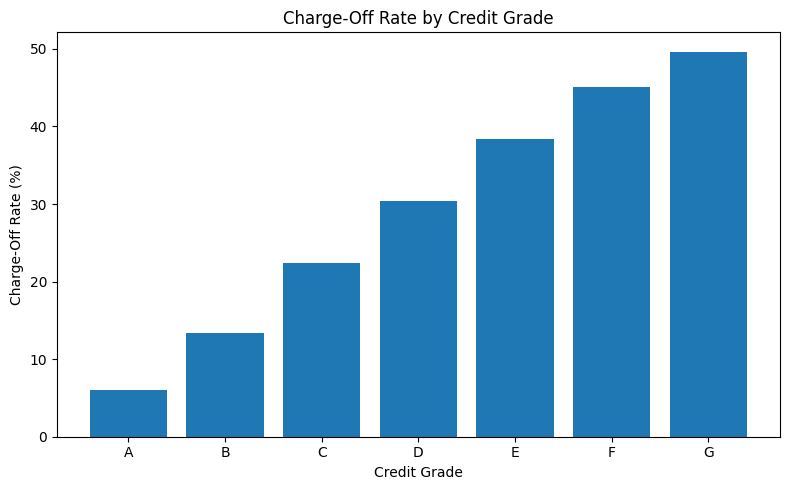

In [52]:
# ============================================================
# 7. VISUALIZING KEY CREDIT RISK PATTERNS
# ============================================================

import matplotlib.pyplot as plt


# ------------------------------------------------------------
# 7.1 Visualizing charge-off rate by credit grade
# ------------------------------------------------------------
# I expect weaker credit grades to show higher charge-off rates.
# This provides a high-level check that the portfolio behaves
# consistently with the assigned risk grades.

plt.figure(figsize=(8, 5))

plt.bar(
    grade_summary["grade"],
    grade_summary["charge_off_rate"] * 100
)

plt.title("Charge-Off Rate by Credit Grade")
plt.xlabel("Credit Grade")
plt.ylabel("Charge-Off Rate (%)")

plt.tight_layout()
plt.show()


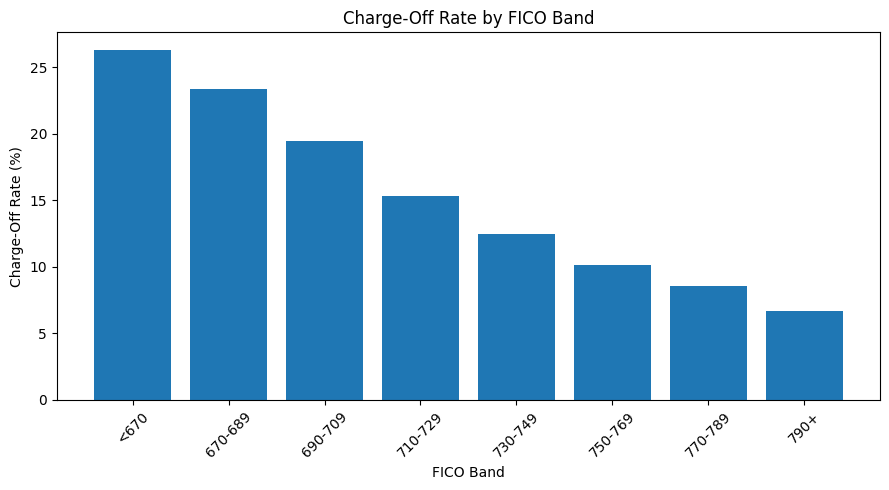

In [53]:
# ------------------------------------------------------------
# 7.2 Visualizing charge-off rate by FICO band
# ------------------------------------------------------------
# I compare historical loan performance across borrower
# credit-score groups.

plt.figure(figsize=(9, 5))

plt.bar(
    fico_summary["fico_band"].astype(str),
    fico_summary["charge_off_rate"] * 100
)

plt.title("Charge-Off Rate by FICO Band")
plt.xlabel("FICO Band")
plt.ylabel("Charge-Off Rate (%)")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

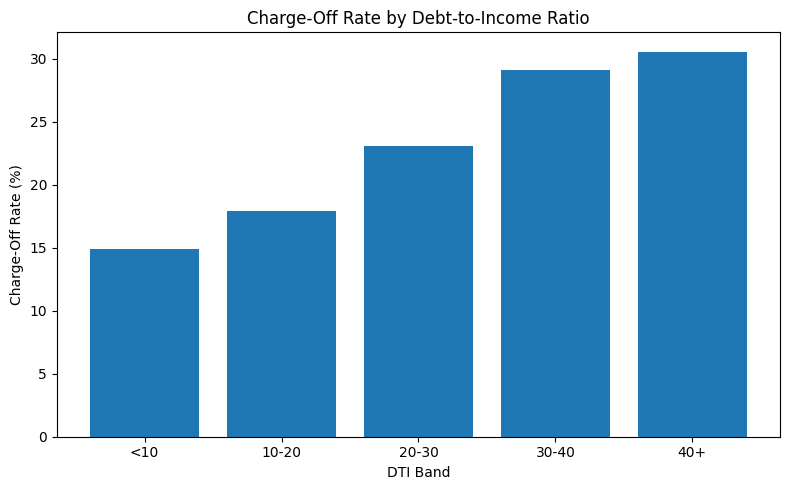

In [54]:
# ------------------------------------------------------------
# 7.3 Visualizing charge-off rate by DTI band
# ------------------------------------------------------------
# This shows whether borrowers with higher debt burdens
# experienced worse historical loan performance.

plt.figure(figsize=(8, 5))

plt.bar(
    dti_summary["dti_band"].astype(str),
    dti_summary["charge_off_rate"] * 100
)

plt.title("Charge-Off Rate by Debt-to-Income Ratio")
plt.xlabel("DTI Band")
plt.ylabel("Charge-Off Rate (%)")

plt.tight_layout()
plt.show()


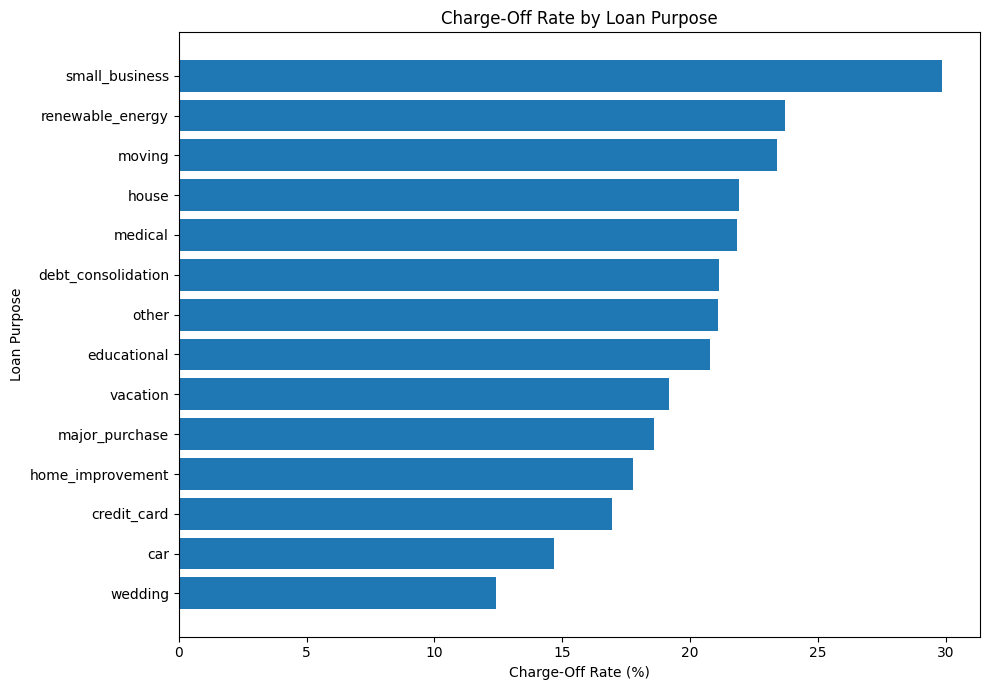

In [55]:
# ------------------------------------------------------------
# 7.4 Visualizing charge-off rate by loan purpose
# ------------------------------------------------------------
# I focus on differences across borrowing purposes to identify
# segments with relatively high or low historical credit risk.

purpose_plot = purpose_summary.sort_values(
    "charge_off_rate",
    ascending=True
)

plt.figure(figsize=(10, 7))

plt.barh(
    purpose_plot["purpose"],
    purpose_plot["charge_off_rate"] * 100
)

plt.title("Charge-Off Rate by Loan Purpose")
plt.xlabel("Charge-Off Rate (%)")
plt.ylabel("Loan Purpose")

plt.tight_layout()
plt.show()

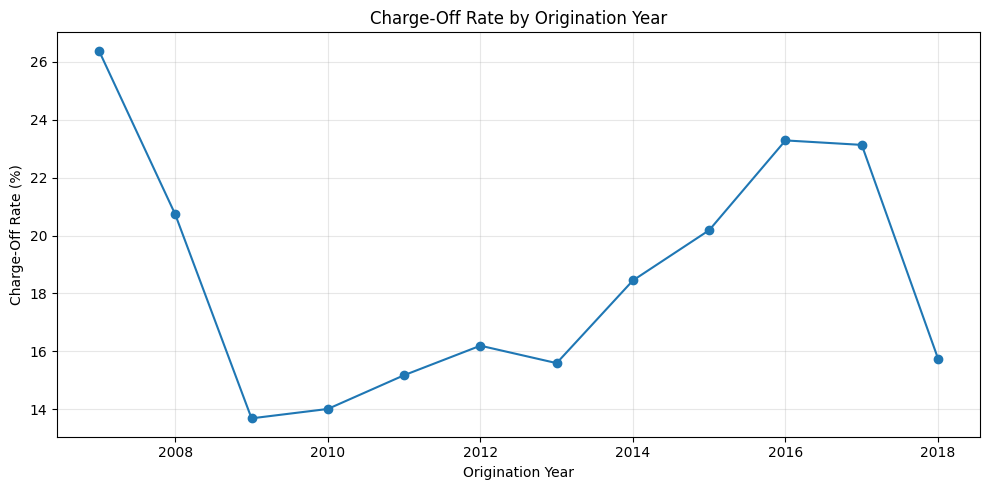

In [56]:
# ------------------------------------------------------------
# 7.5 Visualizing charge-off rate by origination year
# ------------------------------------------------------------
# This chart provides a first view of changes in historical
# performance across loan vintages.
#
# Recent vintages should be interpreted cautiously because
# they may not have fully matured.

plt.figure(figsize=(10, 5))

plt.plot(
    yearly_vintage["origination_year"],
    yearly_vintage["charge_off_rate"] * 100,
    marker="o"
)

plt.title("Charge-Off Rate by Origination Year")
plt.xlabel("Origination Year")
plt.ylabel("Charge-Off Rate (%)")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()



```
# Summary for section 7
```

I visualized the main credit-risk indicators across credit grade, FICO score, DTI, loan purpose and origination vintage. These charts make it easier to identify segments with comparatively high historical charge-off rates and communicate portfolio risk patterns to decision-makers.

# 8. Analyzing Risk Concentration and Interactions

Up to this point, I have mostly analysed one variable at a time. In this section, I combine several dimensions to answer more realistic portfolio-management questions:
- Where is the largest amount of credit risk concentrated?
- Which segments combine high exposure and high charge-off rates?
- How do FICO and DTI interact?
- Does higher loan pricing correspond to higher realized risk?

In [57]:
# ============================================================
# 8. ANALYZING RISK CONCENTRATION AND INTERACTIONS
# ============================================================

import matplotlib.pyplot as plt
import numpy as np


# ------------------------------------------------------------
# 8.1 Measuring risk concentration by loan purpose
# ------------------------------------------------------------
# A high charge-off rate alone does not necessarily make a
# segment important.
#
# A small segment could have a very high charge-off rate but
# contribute relatively little to the overall portfolio.
#
# I therefore combine:
# - portfolio exposure
# - charge-off rate
# - originated amount associated with charged-off loans


purpose_risk = (
    resolved
    .groupby("purpose")
    .agg(
        loan_count=("id", "count"),
        total_exposure=("loan_amnt", "sum"),
        charge_off_rate=("default_flag", "mean")
    )
    .reset_index()
)


# Calculate the originated amount associated with charged-off loans
charged_off_exposure = (
    resolved[resolved["default_flag"] == 1]
    .groupby("purpose")["loan_amnt"]
    .sum()
    .rename("charged_off_exposure")
    .reset_index()
)


purpose_risk = purpose_risk.merge(
    charged_off_exposure,
    on="purpose",
    how="left"
)

purpose_risk["charged_off_exposure"] = (
    purpose_risk["charged_off_exposure"].fillna(0)
)


# Portfolio share based on originated loan amount
purpose_risk["portfolio_share"] = (
    purpose_risk["total_exposure"]
    / purpose_risk["total_exposure"].sum()
)


purpose_risk = purpose_risk.sort_values(
    "charged_off_exposure",
    ascending=False
)

display(purpose_risk)

,purpose,loan_count,total_exposure,charge_off_rate,charged_off_exposure,portfolio_share
2,debt_consolidation,781206,1.189312e+10,0.211542,2.679041e+09,0.612489
1,credit_card,295551,4.375483e+09,0.169311,7.845356e+08,0.225335
4,home_improvement,87684,1.239112e+09,0.177569,2.486742e+08,0.063814
9,other,78263,7.679306e+08,0.210840,1.882997e+08,0.039548
6,major_purchase,29543,3.491250e+08,0.186034,8.253660e+07,0.017980
11,small_business,15575,2.434660e+08,0.298555,7.923135e+07,0.012538
7,medical,15606,1.402980e+08,0.218442,3.482120e+07,0.007225
5,house,7294,1.119955e+08,0.219084,2.571435e+07,0.005768
0,car,14647,1.294341e+08,0.146993,2.247540e+07,0.006666
8,moving,9520,7.476028e+07,0.234139,1.997632e+07,0.003850




```
# Note for section 8
```
What this adds
There is an important distinction between:
Which segment has the highest charge-off rate?

and:
Which segment contributes the most risk to the overall portfolio?

Suppose:
- Small-business loans have a 30% charge-off rate but represent only 2% of exposure.
- Debt-consolidation loans have a 20% charge-off rate but represent 55% of exposure.
The second segment could matter much more to the overall portfolio simply because substantially more money is concentrated there.
One technical point: charged_off_exposure here represents the original loan amount associated with charged-off loans. It is not the bank's actual accounting loss or loss-given-default because this dataset does not give us a complete recovery calculation in this metric.


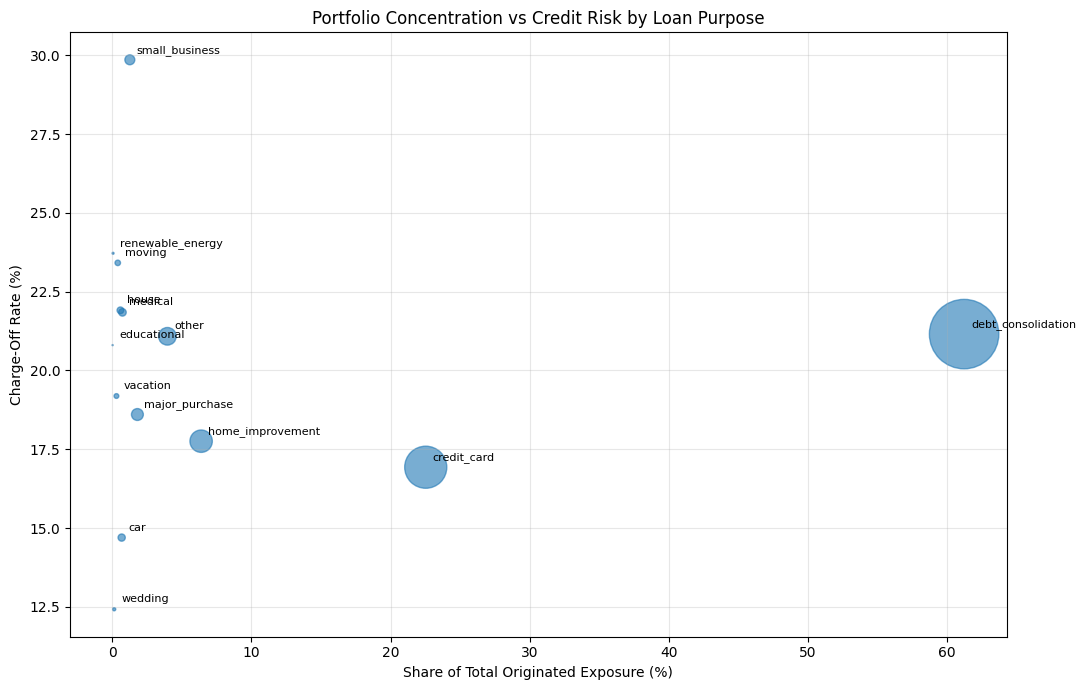

In [58]:
# ------------------------------------------------------------
# 8.2 Visualizing risk concentration:
# exposure vs charge-off rate
# ------------------------------------------------------------
# Each bubble represents a loan purpose.
#
# X-axis  = portfolio share
# Y-axis  = charge-off rate
# Bubble size = total originated exposure
#
# Segments in the upper-right area are particularly important:
# they combine relatively high risk with relatively large
# portfolio concentration.


plt.figure(figsize=(11, 7))

bubble_size = (
    purpose_risk["total_exposure"]
    / purpose_risk["total_exposure"].max()
    * 2500
)

plt.scatter(
    purpose_risk["portfolio_share"] * 100,
    purpose_risk["charge_off_rate"] * 100,
    s=bubble_size,
    alpha=0.6
)


# Add labels for each purpose
for _, row in purpose_risk.iterrows():
    plt.annotate(
        row["purpose"],
        (
            row["portfolio_share"] * 100,
            row["charge_off_rate"] * 100
        ),
        fontsize=8,
        xytext=(5, 5),
        textcoords="offset points"
    )


plt.title("Portfolio Concentration vs Credit Risk by Loan Purpose")
plt.xlabel("Share of Total Originated Exposure (%)")
plt.ylabel("Charge-Off Rate (%)")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [59]:
# ------------------------------------------------------------
# 8.3 Measuring charge-off rates across FICO and DTI together
# ------------------------------------------------------------
# I calculate the historical charge-off rate for every
# combination of FICO band and DTI band.

fico_dti_risk = (
    resolved
    .groupby(
        ["fico_band", "dti_band"],
        observed=True
    )
    .agg(
        loan_count=("id", "count"),
        charge_off_rate=("default_flag", "mean")
    )
    .reset_index()
)

display(fico_dti_risk.head(20))


# ------------------------------------------------------------
# 8.4 Creating a FICO × DTI risk matrix
# ------------------------------------------------------------

risk_matrix = fico_dti_risk.pivot(
    index="fico_band",
    columns="dti_band",
    values="charge_off_rate"
)

display(risk_matrix)

,fico_band,dti_band,loan_count,charge_off_rate
0,<670,<10,44814,0.195140
1,<670,10-20,101187,0.241207
2,<670,20-30,70512,0.305466
3,<670,30-40,20938,0.364457
4,<670,40+,1055,0.389573
5,670-689,<10,69685,0.172821
6,670-689,10-20,174742,0.209881
7,670-689,20-30,130208,0.266781
8,670-689,30-40,39752,0.329694
9,670-689,40+,2041,0.360118


dti_band,<10,10-20,20-30,30-40,40+
fico_band,,,,,
<670,0.195140,0.241207,0.305466,0.364457,0.389573
670-689,0.172821,0.209881,0.266781,0.329694,0.360118
690-709,0.150764,0.170665,0.219130,0.276250,0.282871
710-729,0.123182,0.133040,0.172295,0.229127,0.253438
730-749,0.107905,0.109026,0.140340,0.189325,0.222430
750-769,0.096689,0.086347,0.117296,0.159150,0.167364
770-789,0.083522,0.072562,0.097137,0.155251,0.149254
790+,0.067539,0.057632,0.075542,0.092836,0.174419


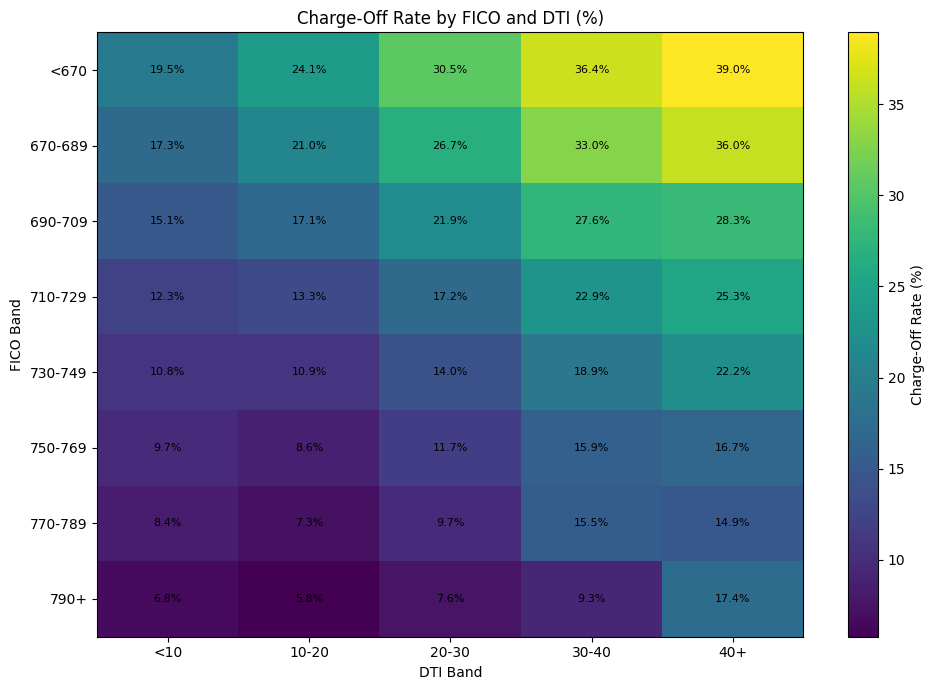

In [60]:


# ------------------------------------------------------------
# 8.5 Visualizing the FICO × DTI risk matrix
# ------------------------------------------------------------
# This heatmap shows how two borrower risk characteristics
# interact instead of analysing them independently.

fig, ax = plt.subplots(figsize=(10, 7))

image = ax.imshow(
    risk_matrix.values * 100,
    aspect="auto"
)

ax.set_xticks(np.arange(len(risk_matrix.columns)))
ax.set_yticks(np.arange(len(risk_matrix.index)))

ax.set_xticklabels(risk_matrix.columns.astype(str))
ax.set_yticklabels(risk_matrix.index.astype(str))

ax.set_xlabel("DTI Band")
ax.set_ylabel("FICO Band")
ax.set_title("Charge-Off Rate by FICO and DTI (%)")


# Add the percentage inside each cell
for i in range(len(risk_matrix.index)):
    for j in range(len(risk_matrix.columns)):

        value = risk_matrix.iloc[i, j]

        if pd.notna(value):
            ax.text(
                j,
                i,
                f"{value:.1%}",
                ha="center",
                va="center",
                fontsize=8
            )


fig.colorbar(
    image,
    ax=ax,
    label="Charge-Off Rate (%)"
)

plt.tight_layout()
plt.show()

In [61]:
# ------------------------------------------------------------
# 8.6 Comparing credit pricing with realized risk
# ------------------------------------------------------------
# I compare average interest rates with actual historical
# charge-off rates across credit grades.
#
# Bubble size represents the number of loans in each grade.

grade_risk_pricing = (
    resolved
    .groupby("grade")
    .agg(
        loan_count=("id", "count"),
        avg_interest_rate=("int_rate", "mean"),
        charge_off_rate=("default_flag", "mean")
    )
    .reset_index()
    .sort_values("grade")
)

display(grade_risk_pricing)

,grade,loan_count,avg_interest_rate,charge_off_rate
0,A,235148,7.113442,0.060422
1,B,393004,10.679231,0.133958
2,C,382179,14.019141,0.224413
3,D,201578,17.709876,0.303768
4,E,94158,21.105309,0.384333
5,F,32294,24.875058,0.451477
6,G,9320,27.540518,0.496567


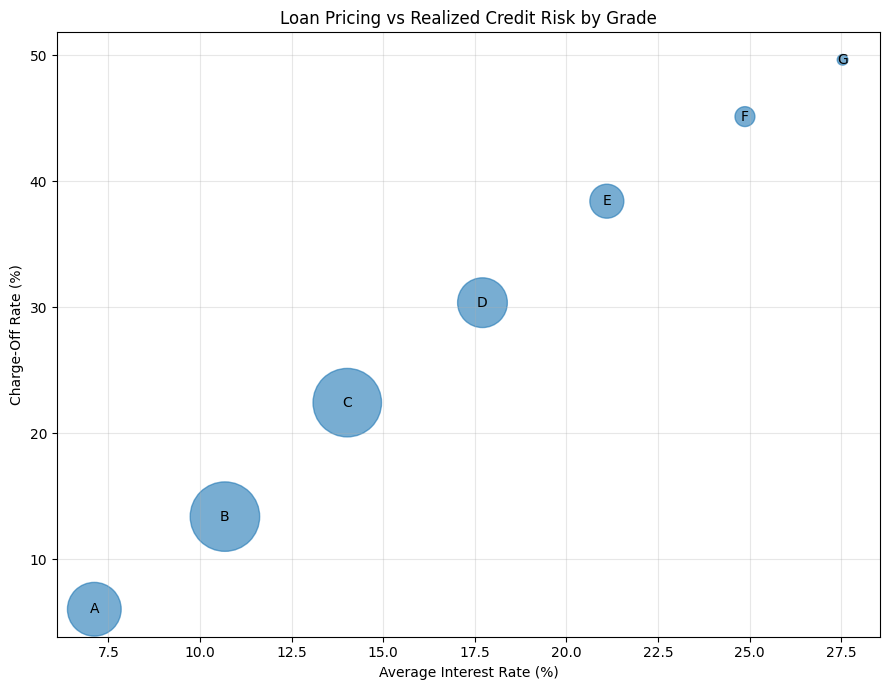

In [62]:
# ------------------------------------------------------------
# 8.7 Visualizing pricing vs realized risk
# ------------------------------------------------------------

#This chart asks:
#Were loans that subsequently experienced higher losses also priced at higher interest rates?

plt.figure(figsize=(9, 7))

bubble_size = (
    grade_risk_pricing["loan_count"]
    / grade_risk_pricing["loan_count"].max()
    * 2500
)

plt.scatter(
    grade_risk_pricing["avg_interest_rate"],
    grade_risk_pricing["charge_off_rate"] * 100,
    s=bubble_size,
    alpha=0.6
)


for _, row in grade_risk_pricing.iterrows():
    plt.annotate(
        row["grade"],
        (
            row["avg_interest_rate"],
            row["charge_off_rate"] * 100
        ),
        ha="center",
        va="center",
        fontsize=10
    )


plt.title("Loan Pricing vs Realized Credit Risk by Grade")
plt.xlabel("Average Interest Rate (%)")
plt.ylabel("Charge-Off Rate (%)")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()



```
# Summary for section 8
```

I have looked at three concepts that matter in credit portfolio management:
- Risk concentration — high risk becomes more important when substantial exposure is concentrated in the same segment.
- Risk interaction — borrower characteristics such as FICO and DTI should not always be interpreted independently.
- Risk-based pricing — borrowers assessed as riskier should generally receive different pricing.


I extended the portfolio analysis by combining exposure, borrower characteristics and pricing. I assessed whether high charge-off segments also represented material portfolio concentrations, examined the interaction between FICO and DTI through a risk matrix, and compared realized credit performance with average loan pricing across credit grades.


# 9. Statistical Analysis

I move from descriptive patterns to testing whether the relationships I observed are statistically meaningful.
Because the dataset is very large, I should not rely only on p-values. With more than a million observations, even very small differences can become statistically significant. I therefore focus on both:
- statistical significance
- effect size / practical importance
I also use a reproducible sample for the regression to keep the Colab session stable.

In [63]:
# ============================================================
# 9. STATISTICAL ANALYSIS
# ============================================================

import numpy as np
import pandas as pd
from scipy import stats
import statsmodels.formula.api as smf


# ------------------------------------------------------------
# 9.1 Comparing borrower characteristics by loan outcome
# ------------------------------------------------------------
# I first compare the average borrower and loan characteristics
# between fully paid and charged-off loans.
#
# This gives me a simple statistical view of whether the two
# groups differ systematically.

comparison_variables = [
    "fico_avg",
    "dti",
    "loan_amnt",
    "annual_inc",
    "int_rate"
]

outcome_comparison = (
    resolved
    .groupby("status_group")[comparison_variables]
    .mean()
    .T
)

display(outcome_comparison)

status_group,Charged Off,Fully Paid
fico_avg,689.825440,700.239519
dti,20.154726,17.804860
loan_amnt,15547.024130,14123.911174
annual_inc,70416.835099,77717.548281
int_rate,15.707227,12.625280


In [64]:
# ------------------------------------------------------------
# 9.2 Testing differences in means
# ------------------------------------------------------------
# I use Welch's t-test because it does not require the two
# outcome groups to have equal variances.
#
# Because the dataset is extremely large, I also calculate
# Cohen's d as an effect-size measure.

#Interpreting Cohen's d
#As a rough guide:
#- |d| < 0.20 → very small difference
#- 0.20–0.50 → small to moderate
#- 0.50–0.80 → moderate to large
#- > 0.80 → large difference
#This is particularly important here because a p-value can be extremely small simply because the dataset is huge.

# I ask - “How large is the actual difference in DTI between charged-off and fully paid borrowers?”



def cohens_d(group_1, group_2):

    group_1 = group_1.dropna()
    group_2 = group_2.dropna()

    pooled_sd = np.sqrt(
        (
            group_1.var(ddof=1) +
            group_2.var(ddof=1)
        ) / 2
    )

    return (
        group_1.mean() - group_2.mean()
    ) / pooled_sd


test_results = []

for variable in comparison_variables:

    fully_paid = resolved.loc[
        resolved["default_flag"] == 0,
        variable
    ].dropna()

    charged_off = resolved.loc[
        resolved["default_flag"] == 1,
        variable
    ].dropna()


    t_stat, p_value = stats.ttest_ind(
        charged_off,
        fully_paid,
        equal_var=False
    )


    effect_size = cohens_d(
        charged_off,
        fully_paid
    )


    test_results.append({
        "variable": variable,
        "fully_paid_mean": fully_paid.mean(),
        "charged_off_mean": charged_off.mean(),
        "difference": charged_off.mean() - fully_paid.mean(),
        "t_statistic": t_stat,
        "p_value": p_value,
        "cohens_d": effect_size
    })


test_results = pd.DataFrame(test_results)

display(test_results)

,variable,fully_paid_mean,charged_off_mean,difference,t_statistic,p_value,cohens_d
0,fico_avg,700.239519,689.825440,-10.414078,-176.020861,0.0,-0.351941
1,dti,17.804860,20.154726,2.349866,93.608650,0.0,0.206361
2,loan_amnt,14123.911174,15547.024130,1423.112956,75.196020,0.0,0.162812
3,annual_inc,77717.548281,70416.835099,-7300.713181,-50.936251,0.0,-0.107024
4,int_rate,12.625280,15.707227,3.081947,296.066180,0.0,0.653105




```
# Multivariate analysis
```
The previous tests examine each variable separately.
Now I want to ask a more realistic question:
Holding other borrower and loan characteristics constant, which factors remain associated with the probability of charge-off?

For this I use logistic regression because the outcome is binary:

0 = Fully Paid
1 = Charged Off


In [65]:
# ------------------------------------------------------------
# 9.3 Preparing the logistic regression sample
# ------------------------------------------------------------
# I use only the variables required for the model and take a
# reproducible random sample to limit memory consumption.


#To keep memory use reasonable, I use a reproducible random sample of 200,000 resolved loans.

regression_columns = [
    "default_flag",
    "fico_avg",
    "dti",
    "loan_amnt",
    "annual_inc",
    "term",
    "grade"
]

regression_data = (
    resolved[regression_columns]
    .dropna()
    .sample(
        n=min(200000, len(resolved)),
        random_state=42
    )
    .copy()
)


# Convert term into a numeric variable
regression_data["term_60_month"] = (
    regression_data["term"]
    .str.contains("60")
    .astype(int)
)


# Rescale continuous variables for easier interpretation
regression_data["fico_10"] = (
    regression_data["fico_avg"] / 10
)

regression_data["dti_5"] = (
    regression_data["dti"] / 5
)

regression_data["loan_amount_1000"] = (
    regression_data["loan_amnt"] / 1000
)

regression_data["income_10000"] = (
    regression_data["annual_inc"] / 10000
)

print(f"Regression sample: {len(regression_data):,} loans")

Regression sample: 200,000 loans


In [66]:
# ------------------------------------------------------------
# 9.4 Estimating the baseline logistic regression
# ------------------------------------------------------------
# I model charge-off probability using borrower characteristics
# and loan term.
#
# I do not include grade or interest rate in the first model
# because they already reflect the lender's own assessment and
# pricing of borrower risk.

model_1 = smf.logit(
    formula="""
        default_flag ~
        fico_10 +
        dti_5 +
        loan_amount_1000 +
        income_10000 +
        term_60_month
    """,
    data=regression_data
).fit()

print(model_1.summary())

Optimization terminated successfully.
         Current function value: 0.470839
         Iterations 6
                           Logit Regression Results                           
Dep. Variable:           default_flag   No. Observations:               200000
Model:                          Logit   Df Residuals:                   199994
Method:                           MLE   Df Model:                            5
Date:                Sun, 11 Oct 2026   Pseudo R-squ.:                 0.05575
Time:                        22:25:57   Log-Likelihood:                -94168.
converged:                       True   LL-Null:                       -99727.
Covariance Type:            nonrobust   LLR p-value:                     0.000
                       coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------
Intercept            6.7618      0.152     44.347      0.000       6.463       7.061
fico_10    

In [67]:
# ------------------------------------------------------------
# 9.5 Converting regression coefficients into odds ratios
# ------------------------------------------------------------

odds_ratios = pd.DataFrame({
    "variable": model_1.params.index,
    "odds_ratio": np.exp(model_1.params),
    "p_value": model_1.pvalues
})

confidence_intervals = np.exp(
    model_1.conf_int()
)

odds_ratios["ci_lower"] = confidence_intervals[0].values
odds_ratios["ci_upper"] = confidence_intervals[1].values

display(odds_ratios)

,variable,odds_ratio,p_value,ci_lower,ci_upper
Intercept,Intercept,864.239546,0.000000e+00,640.983565,1165.256075
fico_10,fico_10,0.883717,0.000000e+00,0.879903,0.887548
dti_5,dti_5,1.075902,7.705906e-112,1.069059,1.082789
loan_amount_1000,loan_amount_1000,1.013986,5.379310e-62,1.012326,1.015648
income_10000,income_10000,0.959901,9.267384e-127,0.956691,0.963121
term_60_month,term_60_month,2.353923,0.000000e+00,2.292413,2.417084
